# Quickstart: splitting merged neurons with PAT

This notebook takes three Hemibrain neurons, overlays them into one point cloud (a synthetic merge error),
and uses a trained Point Affinity Transformer to split the cloud back into individual neurons.

Requirements: `pip install point-affinity-transformer matplotlib`, the Hemibrain data
(see `research/data/README.md`), and a model trained on it, e.g. with
`pat train research/configs/hemibrain.yaml`, which writes the model to `ckpt/hemibrain/model`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import pat
from pat.io import read_swc

device = "cuda" if torch.cuda.is_available() else "cpu"
DATA = Path("../data/hemibrain_v1.2")
MODEL = Path("../ckpt/hemibrain/model")  # output of pat train research/configs/hemibrain.yaml

/home/troidlj@hhmi.org/miniconda3/envs/pat/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load a trained model

In [2]:
model = pat.load_pretrained(MODEL, device=device)
model.config

PATConfig(dim=1024, num_latents=512, depth=24, heads=8, dim_head=64, drop_path_rate=0.1, num_points=4288, feature_dim=0)

## 2. Build a merged point cloud

We overlay three neurons the same way the training data was made: every neuron is centered and moved
60 µm (`data.translate` in the Hemibrain config) in a random direction, so the neurons overlap around the origin.
Coordinates are in µm. `pat` uses coordinates exactly as given, so we normalize them ourselves the same way the
training data was normalized: divided by `data.scale` (659.88367) and not re-centered.

The encoded cloud samples 1024 nodes per neuron, as in training. All skeleton nodes are kept as
query points: they get labels too, even though most of them are not part of the encoded cloud.

In [3]:
rng = np.random.default_rng(0)
root_ids = pd.read_csv(DATA / "affinity/test_small.csv")["root_id"].sample(3, random_state=4).tolist()

nodes, cloud = [], []
for rid in root_ids:
    n = read_swc(DATA / f"swc/{rid}.swc")
    direction = rng.normal(size=3)
    n = n - n.mean(0) + 60 * direction / np.linalg.norm(direction)
    nodes.append(n)
    cloud.append(n[np.sort(rng.integers(0, len(n), 1024))])

all_nodes = np.concatenate(nodes)
cloud = np.concatenate(cloud)
SCALE = 659.88367  # data.scale of the Hemibrain training config
cloud, all_nodes = cloud / SCALE, all_nodes / SCALE

gt = np.concatenate([np.full(len(n), i) for i, n in enumerate(nodes)])
print(f"encoded cloud: {len(cloud)} points, queries: {len(all_nodes)} skeleton nodes of neurons {root_ids}")

encoded cloud: 3072 points, queries: 14789 skeleton nodes of neurons [5812982875, 1889253785, 1292635448]


## 3. Segment

`pat.segment` encodes `cloud` once and labels every query point. Up to `max_anchors` queries are clustered
directly; the rest join the cluster they have the highest mean affinity with. `threshold` is the clustering
distance threshold on `1 - affinity`, and clusters smaller than `min_cluster_size` get label `-1`.

> **Note:** Models trained with the default recipe are sensitive to where the cloud sits relative to the origin,
> and to how evenly points are spread across neurons, because training places every neuron `translate` µm from
> the origin with `samples_per_neuron` nodes each. For real data in brain coordinates, move the cloud to the origin
> (e.g. subtract its centroid) as part of your normalization, and expect lower accuracy than on training-like inputs.

In [4]:
torch.manual_seed(0)
seg = pat.segment(model, cloud, queries=all_nodes, threshold=0.8, min_cluster_size=30)
pred = seg.labels.numpy()

vi, split, merge = pat.metrics.voi(pred, gt)
print(f"found {seg.num_neurons} neurons, {np.mean(pred == -1):.1%} noise")
print(f"VOI {vi:.3f} (split {split:.3f}, merge {merge:.3f}), ARI {pat.metrics.adjusted_rand_score(pred, gt):.3f}")

found 3 neurons, 1.6% noise
VOI 0.242 (split 0.163, merge 0.079), ARI 0.914


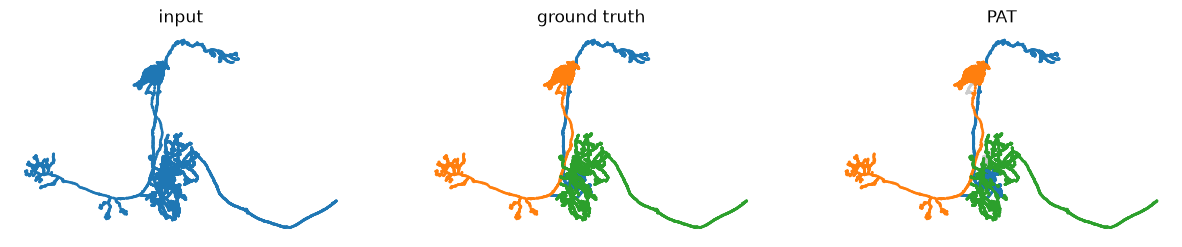

In [5]:
def match_to_gt(pred, gt):
    """Relabel predicted clusters to their best-overlapping ground-truth neuron, for consistent colors."""
    out, used, next_id = np.full_like(pred, -1), set(), gt.max() + 1
    clusters = sorted(np.unique(pred[pred >= 0]), key=lambda k: -np.sum(pred == k))
    for k in clusters:
        counts = np.bincount(gt[pred == k], minlength=gt.max() + 1)
        best = next((int(j) for j in np.argsort(-counts) if counts[j] > 0 and j not in used), None)
        if best is None:
            best, next_id = next_id, next_id + 1
        used.add(best)
        out[pred == k] = best
    return out

def show(ax, pts, labels, title):
    colors = np.array(plt.cm.tab10.colors)
    c = np.where(labels[:, None] >= 0, colors[labels % 10], 0.8)
    ax.scatter(pts[:, 0], pts[:, 1], s=1, c=c)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
show(axes[0], all_nodes, np.zeros_like(gt), "input")
show(axes[1], all_nodes, gt, "ground truth")
show(axes[2], all_nodes, match_to_gt(pred, gt), "PAT")

## 4. Query affinities at any point

The encoded cloud can be queried with any points, not only the encoded ones. `affinity(queries, others)`
returns a `(Q, K)` matrix. Here one reference node is compared with every skeleton node, including the
nodes that are not in the encoded cloud.

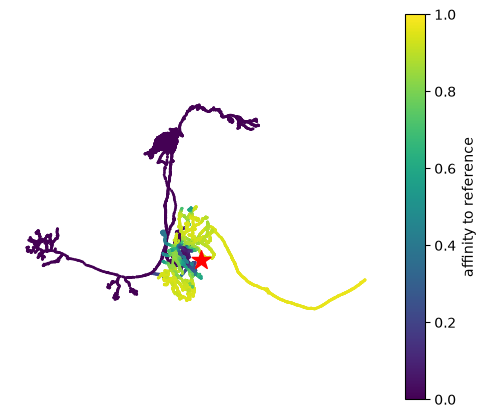

In [6]:
enc = pat.encode(model, cloud)

ref = all_nodes[np.flatnonzero(gt == 2)[-1]]  # a node of the third neuron
aff = enc.affinity(ref[None], all_nodes)[0].cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(all_nodes[:, 0], all_nodes[:, 1], s=1, c=aff, cmap="viridis", vmin=0, vmax=1)
ax.scatter(*ref[:2], s=200, marker="*", c="red")
ax.set_aspect("equal")
ax.axis("off")
fig.colorbar(sc, label="affinity to reference")

Arbitrary point pairs work too, and so do points away from the skeletons. Note that the model was trained
on queries lying on the input cloud, so off-skeleton queries are outside its training distribution.

In [7]:
first = np.cumsum([0] + [len(n) for n in nodes])[:3]  # first node of each neuron
a = all_nodes[[first[0], first[0], first[1]]]
b = all_nodes[[first[0] + 10, first[1], first[2]]]
print("same neuron, neuron 0 vs 1, neuron 1 vs 2:", enc.pair_affinity(a, b).cpu().numpy().round(3))

off_skeleton = a + 15.0 / SCALE  # 15 µm away along every axis
print("off-skeleton queries:", enc.pair_affinity(off_skeleton, b).cpu().numpy().round(3))

same neuron, neuron 0 vs 1, neuron 1 vs 2: [0.834 0.001 0.   ]
off-skeleton queries: [0.602 0.    0.004]
